# Pós Ciência dos Dados - Aplicações de Aprendizado de Máquina

## Atividade 1

Utilize as células a seguir como base para carregar as informações, e a partir da última célula desse modelo, desenvolva seu raciocínio e como seria a abordagem do seu grupo para esse problema. *Não altere as células apresentadas aqui para não danificar a leitura dos dados.*

Os dados estão mascarados, mas basicamente, a variável *y* aponta para quando uma determinada ação vai subir ou vai descer na bolsa.

---

**Nome dos integrantes**

Aluno 1:

Aluno 2:

Aluno 3:

Aluno 4:

---

Lembrem-se, o grupo deve ter no máximo 4 integrantes por grupo, e deverão ser entregues até **08/02 às 23h59** esse notebook preenchido com os experimentos realizados e as conclusões observadas, além de um PDF com 5 slides para o grupo apresentar em 3 minutos para o restante da sala.

In [1]:
import pandas as pd
import numpy as np
from sklearn import metrics, preprocessing, linear_model

# deixa fixo o fator de aleatoriedade
np.random.seed(0)

In [2]:
# carrega os dados
data = pd.read_csv('training_data.csv', header=0)

data = data.drop([
    'id', 'era', 'data_type', 'target_charles', 'target_elizabeth',
    'target_jordan', 'target_ken', 'target_frank', 'target_hillary'],axis=1)

In [3]:
data.head()
#print(data.shape)

,feature1,feature2,feature3,feature4,feature5,feature6,feature7,feature8,feature9,feature10,...,feature42,feature43,feature44,feature45,feature46,feature47,feature48,feature49,feature50,target_bernie
0,0.54836,0.31077,0.37524,0.49490,0.53217,0.48388,0.50220,0.59506,0.55422,0.48578,...,0.32205,0.53407,0.46254,0.56658,0.46022,0.63760,0.55239,0.64054,0.52182,1
1,0.34712,0.40275,0.42747,0.44006,0.47866,0.44055,0.59182,0.68856,0.56543,0.57715,...,0.46215,0.48303,0.35919,0.58709,0.55369,0.64628,0.46029,0.62941,0.55010,1
2,0.50871,0.48639,0.47544,0.40306,0.53436,0.64028,0.51420,0.63232,0.62101,0.48065,...,0.50243,0.51624,0.48028,0.73195,0.42444,0.43228,0.40596,0.54731,0.39061,0
3,0.61363,0.40268,0.53779,0.37045,0.58711,0.59900,0.62428,0.73602,0.43887,0.28383,...,0.54347,0.46995,0.60385,0.56471,0.51203,0.35597,0.53878,0.47776,0.36835,0
4,0.30704,0.47273,0.54495,0.48692,0.47348,0.34695,0.41506,0.61225,0.56853,0.44104,...,0.54050,0.39448,0.29495,0.61935,0.45651,0.53768,0.46431,0.49482,0.60452,1


In [4]:
data.isna().sum()
#data.isin({0}).sum()

feature1         0
feature2         0
feature3         0
feature4         0
feature5         0
feature6         0
feature7         0
feature8         0
feature9         0
feature10        0
feature11        0
feature12        0
feature13        0
feature14        0
feature15        0
feature16        0
feature17        0
feature18        0
feature19        0
feature20        0
feature21        0
feature22        0
feature23        0
feature24        0
feature25        0
feature26        0
feature27        0
feature28        0
feature29        0
feature30        0
feature31        0
feature32        0
feature33        0
feature34        0
feature35        0
feature36        0
feature37        0
feature38        0
feature39        0
feature40        0
feature41        0
feature42        0
feature43        0
feature44        0
feature45        0
feature46        0
feature47        0
feature48        0
feature49        0
feature50        0
target_bernie    0
dtype: int64

In [5]:
# transforma o CSV em numpy
features = [f for f in list(data) if "feature" in f]
X = data[features]
y = data['target_bernie']

In [6]:
# exibe quantidade de amostras e atributos
print(X.shape)
print(y.shape)

(502732, 50)
(502732,)


In [7]:
# a partir daqui é com você...
# 1) separe 30% dos dados para teste e utilize os outros 70% como achar melhor
# 2) lembre-se de aplicar os conceitos vistos em aula

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

# separando o conjunto de treino em validação também
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.30, random_state=42)

In [8]:
print(X_train.shape)
print(y_train.shape)
print(X_val.shape)
print(X_val.shape)

(246338, 50)
(246338,)
(105574, 50)
(105574, 50)


In [33]:
train = X_train[['feature1','feature6','feature9','feature25','feature28','feature29','feature31','feature34','feature36','feature37','feature42','feature46',]]
val = X_val[['feature1','feature6','feature9','feature25','feature28','feature29','feature31','feature34','feature36','feature37','feature42','feature46',]]
test = X_test[['feature1','feature6','feature9','feature25','feature28','feature29','feature31','feature34','feature36','feature37','feature42','feature46',]]
train

,feature1,feature6,feature9,feature25,feature28,feature29,feature31,feature34,feature36,feature37,feature42,feature46
493226,0.45351,0.46729,0.59970,0.43081,0.46397,0.50322,0.54031,0.44313,0.54682,0.31593,0.67662,0.49946
258308,0.47565,0.37692,0.34640,0.47392,0.57826,0.60837,0.61997,0.35924,0.63069,0.56499,0.50793,0.54620
332835,0.18570,0.48398,0.52644,0.80661,0.39304,0.25198,0.47218,0.66111,0.55050,0.46094,0.50723,0.52171
311756,0.25550,0.54320,0.65205,0.41111,0.44241,0.39476,0.57867,0.48762,0.77345,0.39328,0.68975,0.47673
258939,0.56993,0.51614,0.44674,0.46316,0.47772,0.46448,0.49074,0.36992,0.59617,0.47515,0.48713,0.48573
226412,0.58139,0.37061,0.45585,0.59216,0.44706,0.42227,0.47474,0.30475,0.37335,0.71635,0.23958,0.59257
41446,0.46022,0.36296,0.33582,0.44709,0.58331,0.62350,0.85818,0.50784,0.48171,0.51526,0.19401,0.39607
407214,0.27947,0.49148,0.58047,0.60262,0.41618,0.34021,0.38305,0.63762,0.58015,0.52670,0.56508,0.58042
309203,0.59331,0.58860,0.59292,0.47188,0.37454,0.41438,0.45052,0.39052,0.61972,0.45232,0.44034,0.50140
375252,0.53784,0.66020,0.64820,0.40924,0.45854,0.46523,0.46015,0.49508,0.56042,0.34061,0.55074,0.46626


In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
import datetime as dt

print(dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"))
# treinando o modelo 
clf = RandomForestClassifier(n_estimators=100, max_depth=2,random_state=0)
clf.fit(train[['feature25','feature31','feature42']],y_train)

# avaliando o modelo
from sklearn.metrics import accuracy_score
y_pred = clf.predict(val[['feature25','feature31','feature42']])
print(f'Validation score: {accuracy_score(y_val, y_pred) * 100}%') 
# LinearSVC = 0.5136354633990924

# testando o modelo contra os 30% de testes que foram removidos anteriormente
from sklearn.metrics import accuracy_score
y_pred_test = clf.predict(test[['feature25','feature31','feature42']])
print(f'Testing score: {accuracy_score(y_test, y_pred_test) * 100}%')
# LinearSVC = 0.5149714891924148

print(clf.feature_importances_)
dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")

07-02-2019 17:17:01
Validation score: 51.07033928808229%
Testing score: 51.376475268532026%
[0.27558053 0.46276508 0.26165439]


'07-02-2019 17:17:10'

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(data)#vai analisar onde temq mexer para normalizar
data_s = scaler.transform(data)#normaliza os dados
# o ideal é fit no treino e transform no teste
df = pd.DataFrame(data_s)
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,44,45,46,47,48,49,50
count,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,...,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05,5.027320e+05
mean,1.302562e-16,-2.265203e-15,-5.300874e-16,-1.194135e-15,1.178272e-16,-1.650369e-15,-9.527810e-17,-2.548384e-16,6.909498e-16,1.127615e-15,...,5.502646e-16,-1.050087e-15,8.443847e-16,-6.698406e-16,6.899878e-16,1.903454e-15,8.974037e-17,-3.678487e-16,1.893199e-15,2.619778e-16
std,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,...,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00
min,-3.519484e+00,-4.548082e+00,-4.132494e+00,-4.050496e+00,-4.537018e+00,-4.235388e+00,-4.176816e+00,-4.653599e+00,-4.826398e+00,-4.039574e+00,...,-4.110626e+00,-3.752387e+00,-3.582859e+00,-4.515099e+00,-4.574522e+00,-4.574776e+00,-4.493796e+00,-4.552763e+00,-4.900971e+00,-9.998369e-01
25%,-7.023440e-01,-6.681984e-01,-6.851075e-01,-6.703626e-01,-6.608644e-01,-6.894230e-01,-6.731515e-01,-6.621315e-01,-6.539295e-01,-6.873799e-01,...,-6.737485e-01,-7.099594e-01,-6.926043e-01,-6.698926e-01,-6.951353e-01,-6.763368e-01,-6.848308e-01,-6.719648e-01,-6.673075e-01,-9.998369e-01
50%,-6.335799e-03,-6.335987e-03,-2.055422e-02,-5.853735e-03,2.716072e-02,-7.309536e-03,2.183827e-02,3.454624e-02,2.590618e-02,-3.622182e-02,...,8.877501e-04,-3.877829e-02,-2.239616e-02,3.403287e-02,-2.091427e-02,-2.097105e-03,-7.608654e-03,9.934400e-03,8.031310e-03,-9.998369e-01
75%,6.913391e-01,6.619188e-01,6.672580e-01,6.598416e-01,6.865033e-01,6.759330e-01,6.946717e-01,6.980940e-01,6.770015e-01,6.532905e-01,...,6.723124e-01,6.706541e-01,6.706567e-01,6.964775e-01,6.761981e-01,6.748072e-01,6.790984e-01,6.871618e-01,6.739189e-01,1.000163e+00
max,3.987207e+00,4.484870e+00,4.227849e+00,4.846585e+00,4.303980e+00,4.438674e+00,3.841134e+00,3.771068e+00,4.604405e+00,4.513678e+00,...,4.124177e+00,4.230843e+00,3.762693e+00,3.954706e+00,4.237068e+00,4.246830e+00,4.120911e+00,3.977298e+00,4.456639e+00,1.000163e+00


Text(0.5,1,'PCA of FEATURES dataset')

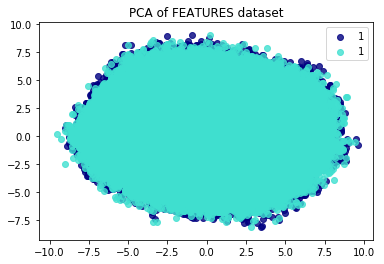

In [12]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
pca = PCA(n_components=2)
X_r = pca.fit_transform(data_s)

colors = ['navy', 'turquoise']
for color, i, target_bernie in zip(colors, [0, 1], data.target_bernie):
    plt.scatter(X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=.8, label=target_bernie)
plt.legend(loc='best', shadow=False, scatterpoints=1)
plt.title('PCA of FEATURES dataset')

In [18]:
# treinando o modelo 
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)#instância do KNN
knn.fit(X_train['feature31'], y_train)

# avaliando o modelo
from sklearn.metrics import accuracy_score
y_pred = knn.predict(X_val['feature31'])
accuracy_score(y_val, y_pred)

ValueError: Expected 2D array, got 1D array instead:
array=[0.54031 0.61997 0.47218 ... 0.20627 0.51803 0.51549].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [19]:
from sklearn.datasets import load_digits
from sklearn.linear_model import Perceptron
import datetime as dt

dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")
X, y = load_digits(return_X_y=True)
clf = Perceptron(tol=1e-3, random_state=0)
clf.fit(X_train, y_train)

Perceptron(alpha=0.0001, class_weight=None, early_stopping=False, eta0=1.0,
    fit_intercept=True, max_iter=None, n_iter=None, n_iter_no_change=5,
    n_jobs=None, penalty=None, random_state=0, shuffle=True, tol=0.001,
    validation_fraction=0.1, verbose=0, warm_start=False, n_iter=None)
y_pred = clf.predict(X_val)
clf.score(y_val, y_pred)
dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")

SyntaxError: keyword argument repeated (<ipython-input-19-b8a2ed8409e2>, line 13)

Text(0.5,1,'PCA of FEATURES dataset')

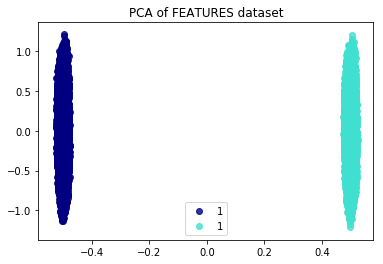

In [11]:
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_r = pca.fit_transform(data)

colors = ['navy', 'turquoise']
for color, i, target_bernie in zip(colors, [0, 1], data.target_bernie):
    plt.scatter(X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=.8, label=target_bernie)
plt.legend(loc='best', shadow=False, scatterpoints=1)
plt.title('PCA of FEATURES dataset')

In [21]:
# embaralhando os dados várias vezes e re-executando o experimento
import numpy as np
from sklearn.model_selection import ShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
ss = ShuffleSplit(n_splits=2, test_size=0.3, uy-
                  random_state=0) # 5 execuções diferentes(5 valores aleatórios) com 20% dos dados para teste
#o ShuffleSplit sempre vai trazer a mesmas 5 divisões, uma diferente da outra, mas sempre essas
acc = []
for train_index, test_index in ss.split(data):#cada vez que passar no for ele passa os índices de treino e de teste 
    knn = KNeighborsClassifier(n_neighbors = 1)
    knn.fit(data[train_index],y[train_index])
    y_pred = knn.predict(data[test_index])
    acc.append(accuracy_score(y_pred,y[test_index]))

acc = np.asarray(acc) # converte pra numpy pra ficar mais simples de usar média e desvio padrão
print('Accuracy - %.2f +- %.2f' % (acc.mean() * 100, acc.std() * 100))#média e desvio padrão

KeyError: '[ 13809 206515 206494 ... 435829 305711 461484] not in index'

In [ ]:
best_model = None
best_accuracy = 0

for k in [1,2,3,4,5]:

    knn = KNeighborsClassifier(n_neighbors = k) # a cada passo, o parâmetro assume um valor
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    print('K:', k, '- ACC:', acc)
    
    if acc > best_accuracy:
        best_model = knn
        best_accuracy = acc
        
y_pred = best_model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print()
print('Melhor modelo:')
print('K:', best_model.get_params()['n_neighbors'], '- ACC:', acc * 100) #corrigir

In [ ]:
data_gs, data_cv, target_gs, target_cv = train_test_split(data, y, test_size=0.95, random_state=42, stratify=y)
import datetime as dt
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")
pipeline = Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier())])

# utiliza-se GridSearchCV para achar os melhores parâmetros
from sklearn.model_selection import GridSearchCV#ao invéz do for K in [1,2,3,4,5]
parameters = {'clf__n_neighbors': [1,2,3,4,5], 'clf__weights' : ['uniform','distance'] } # quais parâmetros(de K e de classificador) e quais valores serão testados
clf = GridSearchCV(pipeline, parameters, cv=3, iid=False) # clf vai armazenar qual foi a melhor configuração
clf.fit(data_gs,target_gs)

print(clf.best_estimator_)
dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")

# utilizando validação cruzada para avaliar o modelo
scores = cross_val_score(clf, data_cv, target_cv, cv=5)

print('Accuracy - %.2f +- %.2f' % (scores.mean() * 100, scores.std() * 100))

dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")

2019-02-01 09:30:37.957484
Pipeline(memory=None,
     steps=[('scaler', StandardScaler(copy=True, with_mean=True, with_std=True)), ('clf', KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
           metric_params=None, n_jobs=1, n_neighbors=5, p=2,
           weights='uniform'))])


In [ ]:
import pandas as pd
import numpy as np


eqp = pd.read_csv('C:/Software Splice/Planilhas/3033.csv', delimiter=';')
print(eqp.head())

arr = np.array(eqp.loc[:,2])
eqp['mês'] = [f.split(sep='/')[1] for f in arr]
print(data.head())